# Webcam + SLIM50_SVD50 segmentation test

ทดลอง pipeline ของ Nano 1 บนคอมก่อน: อ่านภาพจาก webcam → รัน ONNX → แสดง human mask และ overlay ใน notebook โน้ตบุ๊กนี้ยังไม่ส่งข้อมูลไป Nano 2

เลือก kernel ที่ติดตั้ง opencv-python, onnxruntime, numpy และ matplotlib แล้วรันเซลล์ตามลำดับ

In [1]:
from pathlib import Path
import os
import time

import cv2
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt

MODEL_RELATIVE = Path('compression/outputs/jetson_nano/SLIM50_SVD50.onnx')
SEARCH_ROOTS = [Path.cwd(), *Path.cwd().parents]
MODEL_PATH = next((root / MODEL_RELATIVE for root in SEARCH_ROOTS if (root / MODEL_RELATIVE).is_file()), None)
if MODEL_PATH is None:
    raise FileNotFoundError(f'Cannot find {MODEL_RELATIVE}. Start Jupyter in the repository or update MODEL_PATH.')

available = ort.get_available_providers()
providers = ['CUDAExecutionProvider', 'CPUExecutionProvider'] if 'CUDAExecutionProvider' in available else ['CPUExecutionProvider']
session = ort.InferenceSession(str(MODEL_PATH), providers=providers)
print('Model:', MODEL_PATH)
print('Execution providers:', session.get_providers())
print('Inputs:', [(x.name, x.shape, x.type) for x in session.get_inputs()])
print('Outputs:', [(x.name, x.shape, x.type) for x in session.get_outputs()])

Model: D:\Data\AI-edge\compression\outputs\jetson_nano\SLIM50_SVD50.onnx
Execution providers: ['CPUExecutionProvider']
Inputs: [('image', [1, 3, 256, 256], 'tensor(float)'), ('r1', [1, 8, 128, 128], 'tensor(float)'), ('r2', [1, 10, 64, 64], 'tensor(float)'), ('r3', [1, 20, 32, 32], 'tensor(float)'), ('r4', [1, 64, 16, 16], 'tensor(float)')]
Outputs: [('logits', [1, 1, 256, 256], 'tensor(float)'), ('r1o', [1, 8, 128, 128], 'tensor(float)'), ('r2o', [1, 10, 64, 64], 'tensor(float)'), ('r3o', [1, 20, 32, 32], 'tensor(float)'), ('r4o', [1, 64, 16, 16], 'tensor(float)')]


## Initialize model state

The model input is RGB float32 at 256x256 with pixel values in 0-1. Run this cell again to reset the recurrent states.

In [2]:
STATE_SHAPES = [(1, 8, 128, 128), (1, 10, 64, 64), (1, 20, 32, 32), (1, 64, 16, 16)]
states = [np.zeros(shape, dtype=np.float32) for shape in STATE_SHAPES]

def segment_frame(frame_bgr):
    global states
    h, w = frame_bgr.shape[:2]
    resized = cv2.resize(frame_bgr, (256, 256), interpolation=cv2.INTER_LINEAR)
    rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    image = (rgb.astype(np.float32) / 255.0).transpose(2, 0, 1)[None, ...]
    feed = {'image': image}
    feed.update({f'r{i + 1}': state for i, state in enumerate(states)})
    t0 = time.perf_counter()
    logits, *next_states = session.run(['logits', 'r1o', 'r2o', 'r3o', 'r4o'], feed)
    latency_ms = (time.perf_counter() - t0) * 1000
    states = next_states
    logits = cv2.resize(logits[0, 0], (w, h), interpolation=cv2.INTER_LINEAR)
    probability = 1.0 / (1.0 + np.exp(-np.clip(logits, -50, 50)))
    mask = (probability >= 0.5).astype(np.uint8) * 255
    overlay = frame_bgr.copy()
    green = np.zeros_like(frame_bgr)
    green[:, :] = (0, 255, 0)
    person = mask > 0
    overlay[person] = cv2.addWeighted(frame_bgr[person], 0.55, green[person], 0.45, 0)
    return mask, overlay, latency_ms

print('Recurrent state tensors initialized to zero.')

Recurrent state tensors initialized to zero.


## Open the webcam

Change CAMERA_INDEX if your webcam uses another device number. On Windows, DirectShow is selected. Keep this capture open while running step() below.

In [3]:
CAMERA_INDEX = 0
camera = cv2.VideoCapture(CAMERA_INDEX, cv2.CAP_DSHOW) if os.name == 'nt' else cv2.VideoCapture(CAMERA_INDEX)
if not camera.isOpened():
    raise RuntimeError(f'Cannot open webcam index {CAMERA_INDEX}; try another index or close apps using the camera.')
camera.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
camera.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
ok, frame_bgr = camera.read()
if not ok:
    camera.release()
    raise RuntimeError('Webcam opened but did not return a frame.')
print('Webcam ready:', frame_bgr.shape[1], 'x', frame_bgr.shape[0])

Webcam ready: 640 x 480


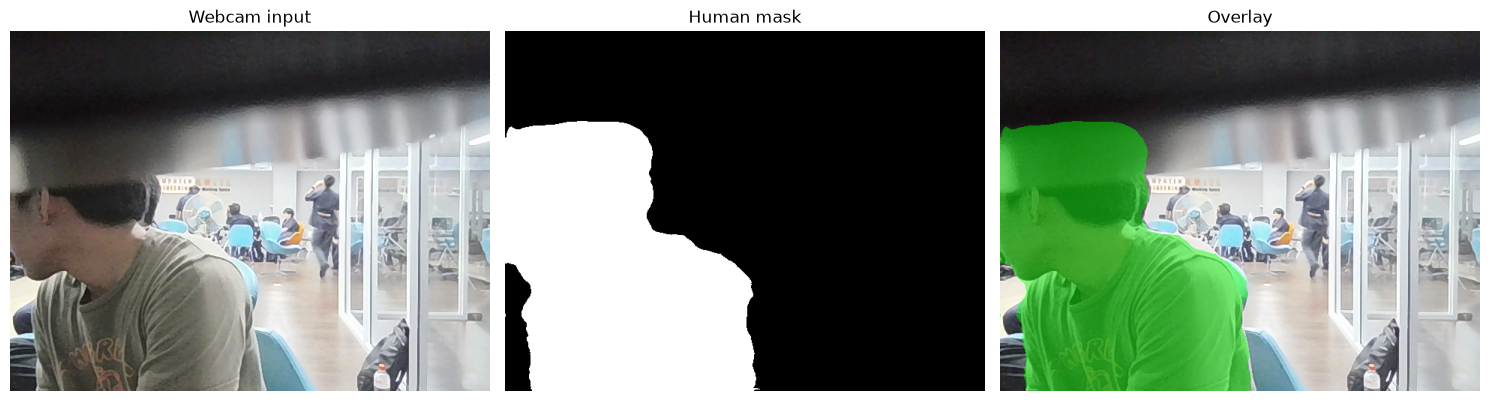

Inference: 49.1 ms | approx. 20.4 FPS (model only)


In [4]:
def step():
    global frame_bgr
    ok, frame_bgr = camera.read()
    if not ok:
        raise RuntimeError('Could not read a frame from the webcam.')
    mask, overlay, latency_ms = segment_frame(frame_bgr)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)); axes[0].set_title('Webcam input')
    axes[1].imshow(mask, cmap='gray', vmin=0, vmax=255); axes[1].set_title('Human mask')
    axes[2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); axes[2].set_title('Overlay')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()
    print(f'Inference: {latency_ms:.1f} ms | approx. {1000 / latency_ms:.1f} FPS (model only)')

step()

Run step() again to process the next webcam frame while preserving recurrent state. Run the next cell when finished to release the webcam. Latency measured on the computer is not a Jetson Nano benchmark.

In [5]:
camera.release()
print('Webcam released.')

Webcam released.
